In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

In [3]:
# Pre-process
FILE_NAME = 'sit_falling.csv'
df = pd.read_csv('./csv/'+FILE_NAME)
df.loc[df['t'] <= 1, 'acc_z'] += 9

# Read 0313
df_0313 = pd.read_csv('./csv/0313data.csv')
df_0313 = df_0313.dropna()
df_0313['Timestamp'] = pd.to_datetime(df_0313['Timestamp'])
df_0313['time_elapsed'] = (df_0313['Timestamp'] - df_0313['Timestamp'].min()).dt.total_seconds().round(2)
df_0313 = df_0313[(df_0313['time_elapsed'] > 11) & (df_0313['time_elapsed'] < 13.5)]

In [4]:
# Low Pass Filter
# Parameters
fs     = 500         # ← your sampling frequency in Hz (critical!)
cutoff = 25          # ← low-pass cutoff frequency in Hz (e.g. 5, 10, 20)
order  = 4              # 2–6 is common; higher = sharper roll-off

# Design Butterworth low-pass filter
nyq = 0.5 * fs
normal_cutoff = cutoff / nyq
b, a = signal.butter(order, normal_cutoff, btype='low', analog=False)

df['acc_x_lowpass'] = signal.filtfilt(b, a, df['acc_x'].values)
df['acc_y_lowpass'] = signal.filtfilt(b, a, df['acc_y'].values)
df['acc_z_lowpass'] = signal.filtfilt(b, a, df['acc_z'].values)

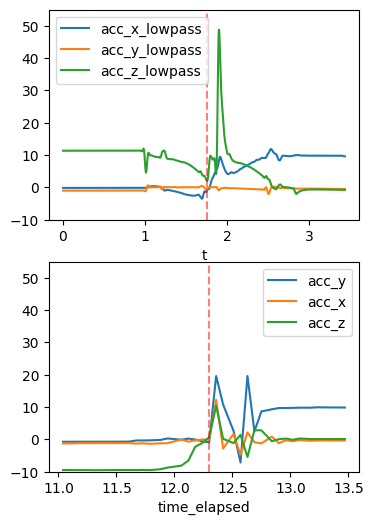

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(4, 6))
df.plot(x='t',y=['acc_x_lowpass','acc_y_lowpass','acc_z_lowpass'], ax=ax1)
df_0313.plot(x='time_elapsed',y=['S8','S7','S9'], ax=ax2, label=['acc_y', 'acc_x', 'acc_z'])
ax1.set_ylim(-10,55)
ax2.set_ylim(-10,55)

def axis_vline(ax1,ax2):
    target_time_real = df_0313.loc[df_0313[df_0313['time_elapsed'].between(12.28, 12.38)]['S9'].idxmin(), 'time_elapsed']
    ax2.axvline(x=target_time_real, color='red', linestyle='--', alpha=0.5)

    target_time_sim = df.loc[df[df['t'].between(1.5, 2)]['acc_z_lowpass'].idxmin(), 't']
    ax1.axvline(x=target_time_sim, color='red', linestyle='--', alpha=0.5)

axis_vline(ax1,ax2)

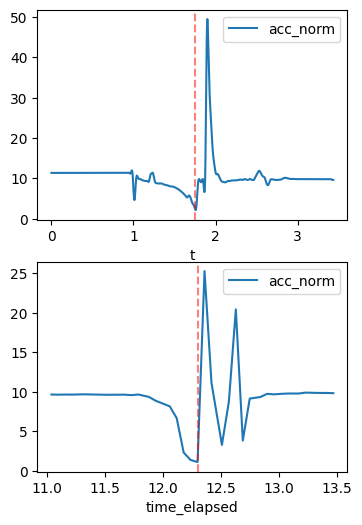

In [6]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(4, 6))
df['acc_norm'] = np.linalg.norm(df[['acc_x_lowpass', 'acc_y_lowpass', 'acc_z_lowpass']], axis=1)
df_0313['acc_norm'] = np.linalg.norm(df_0313[['S8', 'S7', 'S9']], axis=1)
df.plot(x='t',y='acc_norm', ax=ax1)
df_0313.plot(x='time_elapsed',y='acc_norm', ax=ax2)

axis_vline(ax1, ax2)

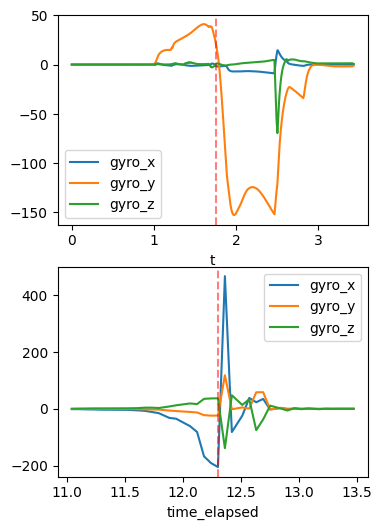

In [7]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(4, 6))
# Convert to degree
gyro_cols = ['gyro_x_degree', 'gyro_y_degree', 'gyro_z_degree']
df[gyro_cols] = np.degrees(df[['gyro_x', 'gyro_y', 'gyro_z']])
df.plot(x='t',y=gyro_cols, ax=ax1, label=['gyro_x', 'gyro_y', 'gyro_z'])
df_0313.plot(x='time_elapsed',y=['S4','S5','S6'], ax=ax2, label=['gyro_x', 'gyro_y', 'gyro_z'])

axis_vline(ax1,ax2)

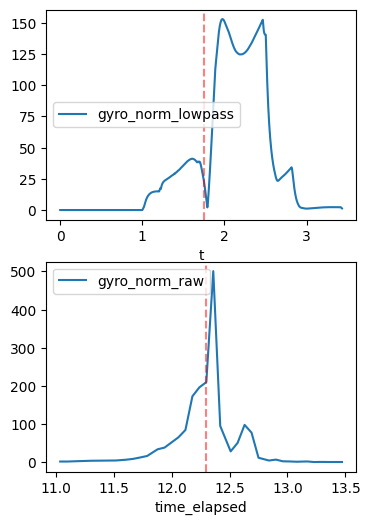

In [8]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(4, 6))

# 1. Update first plot: use gyro lowpass columns
df['gyro_norm'] = np.linalg.norm(df[['gyro_x_degree', 'gyro_y_degree', 'gyro_z_degree']], axis=1)
df.plot(x='t', y='gyro_norm', ax=ax1, label='gyro_norm_lowpass')

# 2. Update second plot: use S4, S5, S6 (the gyro sensors)
df_0313['gyro_norm'] = np.linalg.norm(df_0313[['S4', 'S5', 'S6']], axis=1)
df_0313.plot(x='time_elapsed', y='gyro_norm', ax=ax2, label='gyro_norm_raw')

axis_vline(ax1,ax2)

In [9]:
print(df.columns,df_0313.columns)

Index(['t', 'acc_x', 'acc_y', 'acc_z', 'gyro_x', 'gyro_y', 'gyro_z', 'tof',
       'acc_x_lowpass', 'acc_y_lowpass', 'acc_z_lowpass', 'acc_norm',
       'gyro_x_degree', 'gyro_y_degree', 'gyro_z_degree', 'gyro_norm'],
      dtype='object') Index(['Timestamp', 'S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9',
       'time_elapsed', 'acc_norm', 'gyro_norm'],
      dtype='object')
